# Daily Challenge — Bank Customer Churn

Complete the four hypothesis tests in the course starter, then build and evaluate a churn classifier. Keep the supplied **Inferential Statistics.zip** next to the notebook, or upload it to Colab. Run the cells in order. The notebook downloads the archive if it is absent.

In [1]:
# Step 1. Read the course CSV directly from its ZIP and inspect the data.
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
archive = Path("Inferential Statistics.zip")
url = ("https://media.githubusercontent.com/media/devtlv/Datasets-GEN-AI-Bootcamp/"
       "main/Week%205/Day%204%20-%20Statistics%20for%20Machine%20Learning/Inferential%20Statistics.zip")
source = archive
if not archive.exists():
    with urlopen(url, timeout=30) as response:
        source = BytesIO(response.read())
with ZipFile(source) as zipped, zipped.open("Churn_Modelling.csv") as csv:
    df = pd.read_csv(csv)
print(df.head().to_string(index=False))
print(f"Shape: {df.shape} | Missing values: {df.isna().sum().sum()} | Duplicates: {df.duplicated().sum()}")
assert df["Exited"].isin([0, 1]).all()

# Step 2. Split the descriptive analysis by the observed churn label.
df_0 = df.loc[df["Exited"].eq(0)].copy()
df_1 = df.loc[df["Exited"].eq(1)].copy()
print(f"Stayed: {len(df_0):,} | Exited: {len(df_1):,} | Churn rate: {df['Exited'].mean():.2%}")

 RowNumber  CustomerId  Surname  CreditScore Geography Gender  Age  Tenure   Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited
         1    15634602 Hargrave          619    France Female   42       2      0.00              1          1               1        101348.88       1
         2    15647311     Hill          608     Spain Female   41       1  83807.86              1          0               1        112542.58       0
         3    15619304     Onio          502    France Female   42       8 159660.80              3          1               0        113931.57       1
         4    15701354     Boni          699    France Female   39       1      0.00              2          0               0         93826.63       0
         5    15737888 Mitchell          850     Spain Female   43       2 125510.82              1          1               1         79084.10       0
Shape: (10000, 14) | Missing values: 0 | Duplicates: 0
Stayed: 7,963 | Exited: 2,037 | C

## Applying inferential statistics

For age, credit score, balance and estimated salary, the null hypothesis is that customers who stayed and customers who exited have equal population means. The alternative is two-sided. Use Welch's t-test at α = 0.05 because the groups have unequal sizes and may have unequal variances. This assumes independent customer observations. A small p-value supports a difference in means. It gives neither the size of the difference nor evidence that the feature causes churn.

In [2]:
# Step 3. Reuse the same plots and summary calculations for each hypothesis.
# Normalizing within groups makes distributions comparable across group sizes.
alpha = 0.05
def samples(column, nonzero=False):
    stayed = df_0[column].dropna().to_numpy()
    exited = df_1[column].dropna().to_numpy()
    if nonzero:
        stayed, exited = stayed[stayed > 0], exited[exited > 0]
    return stayed, exited

def plot_groups(column, nonzero=False):
    stayed, exited = samples(column, nonzero)
    bins = np.histogram_bin_edges(np.concatenate([stayed, exited]), bins=30)
    fig, ax = plt.subplots(figsize=(7.5, 4))
    for values, label, color in [(stayed, "Stayed", "#256280"), (exited, "Exited", "#b35732")]:
        sns.histplot(values, bins=bins, stat="probability", label=label,
                     color=color, element="step", fill=False, ax=ax)
    ax.set(title=column + (" among customers with positive balances" if nonzero else " by churn status"),
           xlabel=column, ylabel="Fraction of group per bin")
    ax.legend()
    fig.tight_layout()
    plt.show()

def compare(column, nonzero=False):
    stayed, exited = samples(column, nonzero)
    result = stats.ttest_ind(exited, stayed, equal_var=False)
    lower, upper = result.confidence_interval()
    delta = exited.mean() - stayed.mean()
    pooled_sd = np.sqrt(((len(stayed)-1)*stayed.var(ddof=1) + (len(exited)-1)*exited.var(ddof=1))
                        / (len(stayed) + len(exited) - 2))
    print(f"Stayed: n={len(stayed):,}, mean={stayed.mean():,.2f}, SD={stayed.std(ddof=1):,.2f}")
    print(f"Exited: n={len(exited):,}, mean={exited.mean():,.2f}, SD={exited.std(ddof=1):,.2f}")
    print(f"Exited minus stayed: {delta:+,.2f} (95% CI {lower:,.2f} to {upper:,.2f})")
    print(f"Welch t={result.statistic:.3f}, p={result.pvalue:.4g}")
    print("Reject equal means." if result.pvalue < alpha else "Fail to reject equal means.")
    return {"gap": delta, "p": result.pvalue, "d": delta / pooled_sd}

## Hypothesis 1: Age

Stayed: n=7,963, mean=37.41, SD=10.13
Exited: n=2,037, mean=44.84, SD=9.76
Exited minus stayed: +7.43 (95% CI 6.95 to 7.91)
Welch t=30.419, p=4.713e-179
Reject equal means.


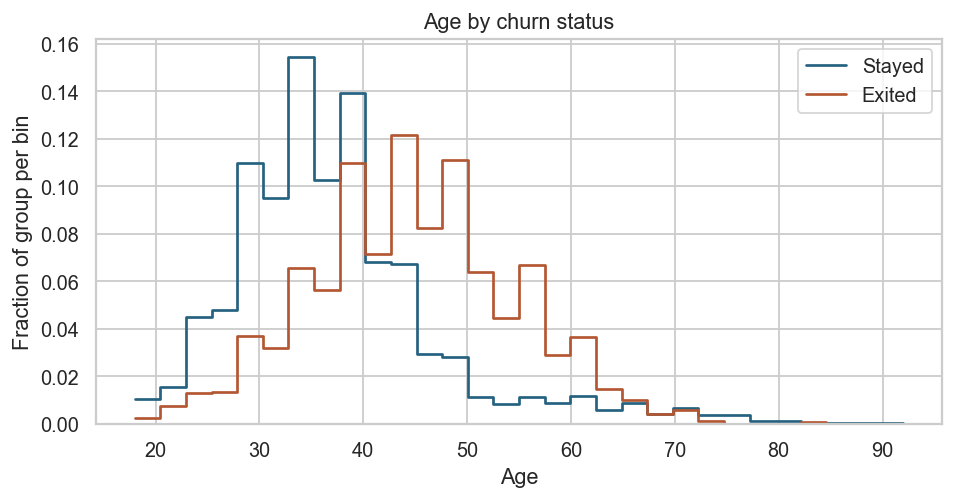

In [3]:
# Step 4. Plot ages and report sample means, SDs and the Welch test.
plot_groups("Age")
age = compare("Age")

### Using Bootstrapping

In [4]:
# Step 5. Bootstrap with replacement in batches to bound memory usage.
def bs_choice(data, statistic, size, rng, batch_size=128):
    estimates = np.empty(size)
    for start in range(0, size, batch_size):
        size_now = min(batch_size, size - start)
        draws = rng.choice(data, size=(size_now, len(data)), replace=True)
        estimates[start:start + size_now] = statistic(draws, axis=1)
    return estimates

def bootstrap_test(column, repetitions=10_000, seed=42):
    stayed, exited = samples(column)
    observed = exited.mean() - stayed.mean()
    pooled_mean = np.concatenate([stayed, exited]).mean()
    # Shift both groups to the same mean to generate samples under the null.
    stayed_null = stayed - stayed.mean() + pooled_mean
    exited_null = exited - exited.mean() + pooled_mean
    rng = np.random.default_rng(seed)
    boot_stayed = bs_choice(stayed_null, np.mean, repetitions, rng)
    boot_exited = bs_choice(exited_null, np.mean, repetitions, rng)
    differences = boot_exited - boot_stayed
    # A two-sided p-value counts differences at least as extreme in either
    # direction. Add one so the finite simulation cannot report p=0.
    extreme = np.count_nonzero(np.abs(differences) >= abs(observed))
    p_value = (extreme + 1) / (repetitions + 1)
    print(f"Observed mean difference: {observed:+,.2f}")
    print(f"SD of bootstrapped means (stayed/exited): {boot_stayed.std(ddof=1):.3f} / {boot_exited.std(ddof=1):.3f}")
    print(f"SD of bootstrap differences: {differences.std(ddof=1):.3f}")
    print(f"Extreme draws: {extreme:,}/{repetitions:,} | Adjusted p: {p_value:.4g}")
    return p_value

age_boot = bootstrap_test("Age")

Observed mean difference: +7.43
SD of bootstrapped means (stayed/exited): 0.114 / 0.214
SD of bootstrap differences: 0.242
Extreme draws: 0/10,000 | Adjusted p: 9.999e-05


Reject equal mean ages. The exited group averaged **7.43 years older**. Both Welch's test and the null-centered bootstrap support a difference.

## Hypothesis 2: Credit Score

Stayed: n=7,963, mean=651.85, SD=95.65
Exited: n=2,037, mean=645.35, SD=100.32
Exited minus stayed: -6.50 (95% CI -11.34 to -1.66)
Welch t=-2.635, p=0.008465
Reject equal means.


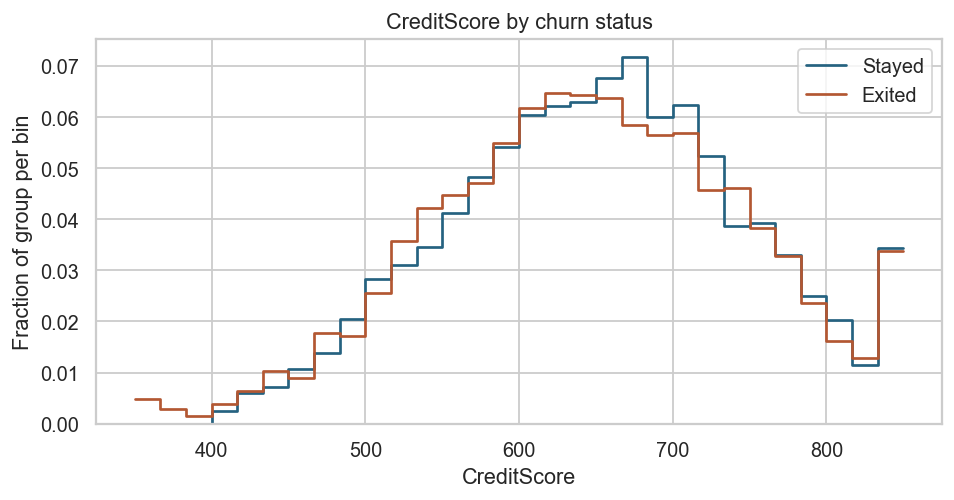

In [5]:
# Step 6. Compare credit scores with the same two-sided Welch test.
plot_groups("CreditScore")
credit = compare("CreditScore")

Credit scores differ at the unadjusted 5% threshold (p = 0.00846), but the gap is only **6.50 points**. See the multiple-testing summary below.

## Hypothesis 3: Balance

Stayed: n=7,963, mean=72,745.30, SD=62,848.04
Exited: n=2,037, mean=91,108.54, SD=58,360.79
Exited minus stayed: +18,363.24 (95% CI 15,476.26 to 21,250.22)
Welch t=12.471, p=6.319e-35
Reject equal means.
Stayed with zero balance: 39.14%
Exited with zero balance: 24.55%
Stayed: n=4,846, mean=119,535.86, SD=29,944.93
Exited: n=1,537, mean=120,746.97, SD=30,555.19
Exited minus stayed: +1,211.11 (95% CI -534.50 to 2,956.71)
Welch t=1.360, p=0.1738
Fail to reject equal means.


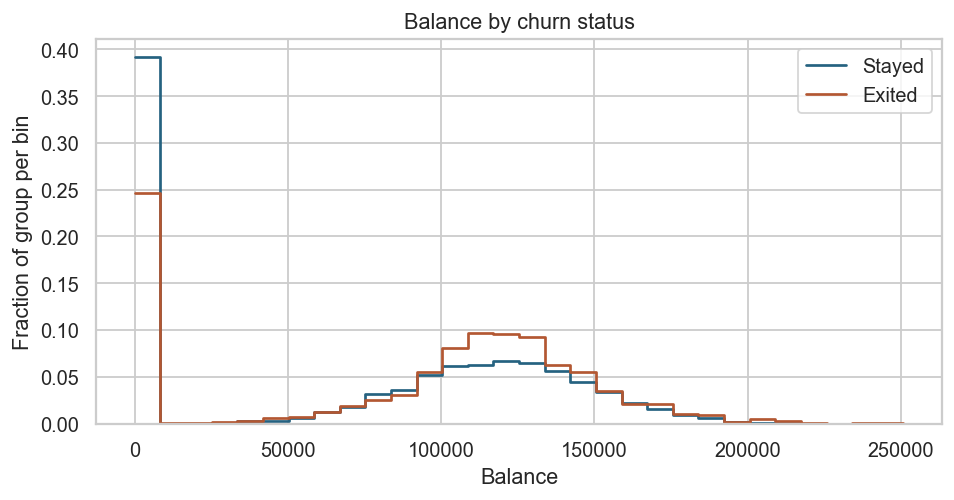

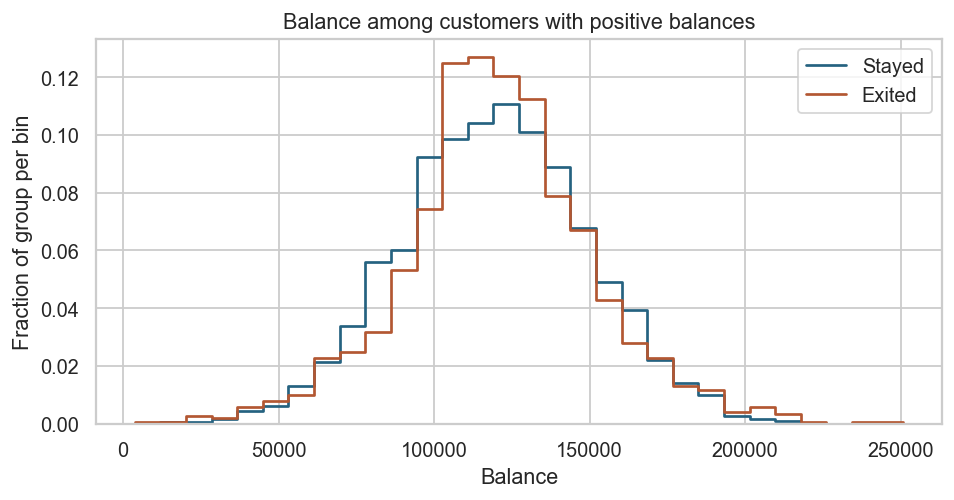

In [6]:
# Step 7. Compare all balances, then repeat using only positive balances.
plot_groups("Balance")
balance = compare("Balance")
for label, group in [("Stayed", df_0), ("Exited", df_1)]:
    print(f"{label} with zero balance: {group['Balance'].eq(0).mean():.2%}")
plot_groups("Balance", nonzero=True)
balance_nonzero = compare("Balance", nonzero=True)

The overall mean balance difference was **18,363**. Among customers with positive balances, the difference was **1,211** (p = 0.174). The restricted analysis answers a different question, and the unequal shares of zero balances help explain why the overall gap is larger.

## Hypothesis 4: Estimated Salary

Stayed: n=7,963, mean=99,738.39, SD=57,405.59
Exited: n=2,037, mean=101,465.68, SD=57,912.42
Exited minus stayed: +1,727.29 (95% CI -1,087.08 to 4,541.66)
Welch t=1.203, p=0.2289
Fail to reject equal means.
Observed mean difference: +1,727.29
SD of bootstrapped means (stayed/exited): 645.420 / 1287.596
SD of bootstrap differences: 1439.794
Extreme draws: 2,277/10,000 | Adjusted p: 0.2278


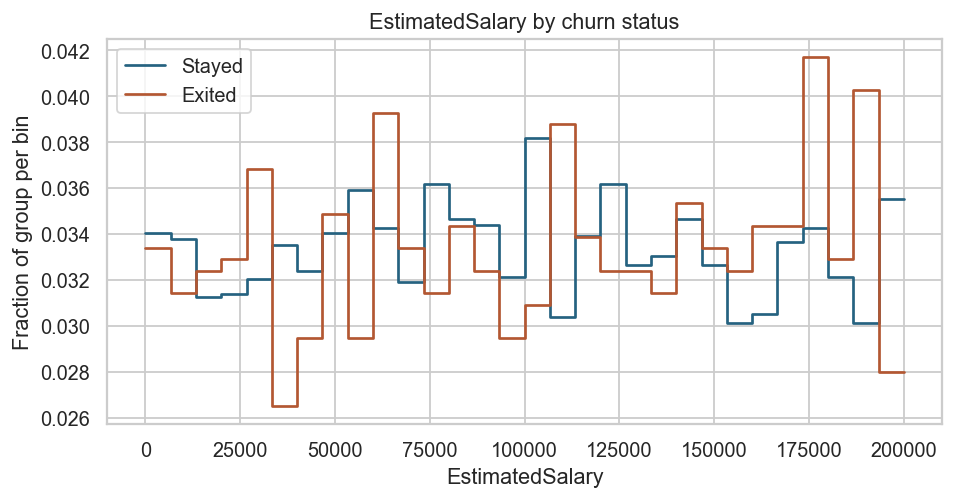

In [7]:
# Step 8. Run the Welch test for salary and check it with the bootstrap.
plot_groups("EstimatedSalary")
salary = compare("EstimatedSalary")
salary_boot = bootstrap_test("EstimatedSalary", seed=43)

Fail to reject equal mean estimated salaries. The Welch p-value was **0.229** and the bootstrap p-value was **0.228**. The tests leave room for a difference within the sampling uncertainty.

In [8]:
# Step 9. Rank the four primary tests by standardized mean difference.
# Bonferroni multiplies each p-value by four to account for the four tests.
tests = pd.DataFrame({"Age": age, "CreditScore": credit, "Balance": balance,
                      "EstimatedSalary": salary}).T
tests["Bonferroni p"] = (tests["p"] * len(tests)).clip(upper=1)
tests = tests.sort_values("d", key=abs, ascending=False)
print(tests.to_string(float_format=lambda value: f"{value:.4g}"))

                      gap          p        d  Bonferroni p
Age                  7.43 4.713e-179   0.7391    1.885e-178
Balance         1.836e+04  6.319e-35   0.2964     2.527e-34
CreditScore        -6.502   0.008465 -0.06729       0.03386
EstimatedSalary      1727     0.2289  0.03003        0.9157


## Predict churn on held-out customers

Age has the largest standardized mean difference of the four tested features. To check predictive usefulness in a multivariable model, train a logistic regression on customer attributes and compare it with a majority-class baseline.

Majority baseline accuracy      0.7965
Logistic regression accuracy    0.8080
Precision                       0.5891
Recall                          0.1867
ROC AUC                         0.7748
Average precision               0.4789
Age               0.1444
IsActiveMember    0.0572
Geography         0.0196
Gender            0.0194
Balance           0.0026


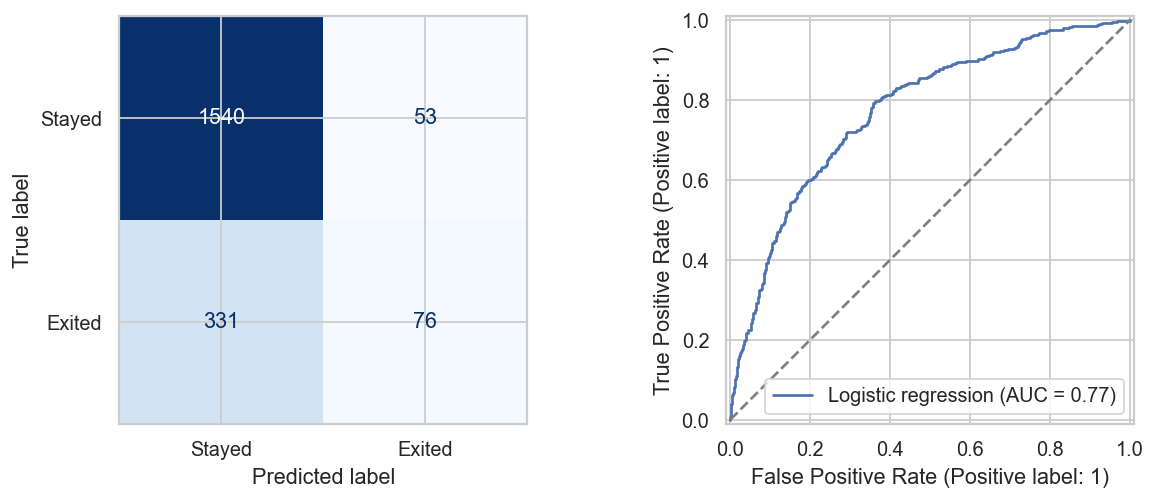

In [9]:
# Step 10. Remove row identifiers and surnames. Split before imputation,
# standardization, or one-hot encoding so test rows stay unseen during fit.
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = df.drop(columns=["Exited", "RowNumber", "CustomerId", "Surname"])
y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
numeric = [column for column in X_train if column not in categorical]
preprocess = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("category", make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore")), categorical),
])
model = make_pipeline(preprocess, LogisticRegression(max_iter=2000))
model.fit(X_train, y_train)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

# Step 11. Accuracy can be high when most customers stay. Also check
# positive-class recall, precision, ROC AUC and average precision.
predicted = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]
scores = pd.Series({
    "Majority baseline accuracy": dummy.score(X_test, y_test),
    "Logistic regression accuracy": accuracy_score(y_test, predicted),
    "Precision": precision_score(y_test, predicted, zero_division=0),
    "Recall": recall_score(y_test, predicted),
    "ROC AUC": roc_auc_score(y_test, probabilities),
    "Average precision": average_precision_score(y_test, probabilities),
})
print(scores.round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=["Stayed", "Exited"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
fig.tight_layout()
plt.show()

# Step 12. Shuffle one input at a time and measure its effect on test AUC.
importance = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                                    n_repeats=8, random_state=42)
ranked = pd.Series(importance.importances_mean, index=X.columns).sort_values(ascending=False)
print(ranked.head(5).round(4).to_string())

## Final conclusion

**Age** showed the largest standardized separation among the four tested variables. **Age** caused the largest drop in held-out ROC AUC when shuffled in this logistic regression. Permutation importance describes this model and split. Correlated features can share predictive information.

The classifier reached **ROC AUC 0.775** and found **18.7%** of churners at its default threshold. If retention staff can contact only a fixed number of customers, evaluate precision and recall among the top-scored customers on later data. A randomized outreach test can show whether contact actually reduces churn.